# Problem 4.2

Consider the function

$$f(x_1, x_2, x_3) = x_1^2 x_2 + 4 x_2^4 - x_2 x_3 + x_3^{-1},$$

and answer the following:

a. Find the gradient of this function. Where is the gradient not defined?

b. Calculate the directional derivative of the function at $x_A = (2, -1, 5)$ in the direction $p = [6, -2, 3]$.

c. Find the Hessian of this function. Is the curvature in the direction $p$ positive or negative?

d. Write the second-order Taylor series expansion of this function. Plot the Taylor series function along the $p$ direction and compare it to the actual function.

In [36]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [37]:
def f(x):
    x1, x2, x3 = x
    return x1 ** 2 * x2 + 4 * x2 ** 4 - x2 * x3 + 1 / x3

x_a = np.array([2.0, -1.0, 5.0])
p_x = np.array([6.0, -2.0, 3.0])
p = p_x/ np.linalg.norm(p_x)  # normalize p

In [38]:
# a) define the gradient of the function f
# the gradient is undefined at x3 = 0

def grad(x):
    x1, x2, x3 = x
    df_dx1 = 2*x1 * x2
    df_dx2 = x1**2 + 16*x2**3 - x3
    df_dx3 = -x2 - 1/(x3**2)
    return np.array([df_dx1, df_dx2, df_dx3])

In [39]:
# b) find derrivative at x_a in direction p

result = np.dot(grad(x_a), p)

print(f"The derivative of f at x_a in the direction of p is: {result:.3f}")

The derivative of f at x_a in the direction of p is: 1.840


In [40]:
# c) find the hessian and calculate the curvature at x_a in direction p

def hessian(x):
    x1, x2, x3 = x
    d2f_dx1dx1 = 2*x2
    d2f_dx1dx2 = 2*x1
    d2f_dx1dx3 = 0
    d2f_dx2dx1 = 2*x1
    d2f_dx2dx2 = 48*x2**2
    d2f_dx2dx3 = -1
    d2f_dx3dx1 = 0
    d2f_dx3dx2 = -1
    d2f_dx3dx3 = 2/(x3**3)
    
    return np.array([[d2f_dx1dx1, d2f_dx1dx2, d2f_dx1dx3],
                     [d2f_dx2dx1, d2f_dx2dx2, d2f_dx2dx3],
                     [d2f_dx3dx1, d2f_dx3dx2, d2f_dx3dx3]])

result_hessian = hessian(x_a)
curvature = np.dot(p, np.dot(result_hessian, p))
eigenvalues = np.linalg.eigvals(result_hessian)

print(f"The curvature of f at x_a in the direction of p is: {curvature:.3f}")

print(f"The eigenvalues of the Hessian at x_a are: {np.round(eigenvalues, 3)}")

The curvature of f at x_a in the direction of p is: 0.738
The eigenvalues of the Hessian at x_a are: [ 4.8339e+01+0.j -2.3210e+00+0.j -2.0000e-03+0.j]


In [41]:
# d) second order taylor expansion of f at x_a in direction p. plot and compare to the real function f

def taylor_expansion(x_a, p):
    f_xa = f(x_a)
    grad_xa = grad(x_a)
    hessian_xa = hessian(x_a)
    
    return f_xa + np.dot(grad_xa, p) + 0.5 * np.dot(p, np.dot(hessian_xa, p))

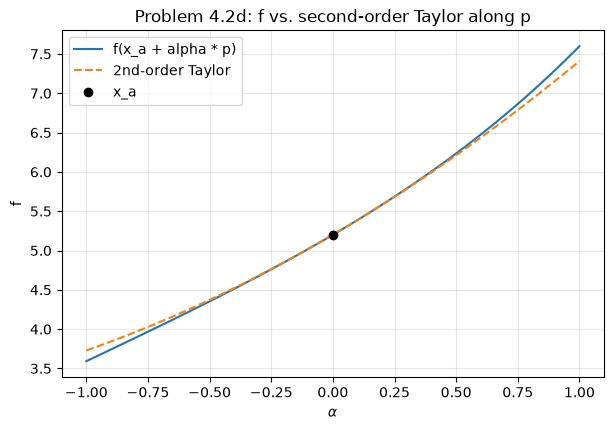

In [42]:
# d) plot skeleton: f vs. 2nd-order Taylor along the line x(alpha) = x_a + alpha * p

# choose the alpha range (alpha = 0 is x_a)
alphas = np.linspace(-1,1,100) 

# evaluate the true function and the Taylor model at each alpha
f_true   = np.array([f(x_a + alpha * p) for alpha in alphas])
f_taylor = np.array([taylor_expansion(x_a, alpha * p) for alpha in alphas])

fig, ax = plt.subplots(figsize=(7, 4.5))
# plot both curves
ax.plot(alphas, f_true, label="f(x_a + alpha * p)")
ax.plot(alphas, f_taylor, "--", label="2nd-order Taylor")

# mark the expansion point (alpha = 0)
ax.plot(0, f(x_a), "ko", label="x_a")

ax.set_xlabel(r"$\alpha$")
ax.set_ylabel("f")
ax.set_title("Problem 4.2d: f vs. second-order Taylor along p")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


## Results

see above. finding the gradient and the hessian is quite simple. also finding the gradient and the hessian at a point in a specified direction.  
in b) we have to make sure that x3 is not 0 as the gradient is undefined there.  
in c) the curvature at x_a in direction p is positive (0.738). the hessian is indefinite here.
in d) on the plot we can see that the talyor expansion close to x_a matches f closely but deviates more and more as we go further away from x_a. the full taylor expansion is T(alpha) = 5,2 + 12.88*alpha + 18.07*alpha^2

## Interpretation

finding the gradient and the hessian for a function with three variables is simple to do analyticaly. but the fact that there are already 6 unique functions for the hessian shows that we need a simpler way of calculating it for more complicated problems. quasi newton is used to reduce the cost of computing these second derrivatives for expensive models.
the hessian contains a lot of information. making the most of it is crucial to a good optimization algorithm.